In [3]:
import xarray as xr
import pandas as pd
import numpy as np

# 1. 加载两个气象文件
ds_instant = xr.open_dataset('instant.nc')
ds_accum = xr.open_dataset('accum.nc')

# 合并为一个数据集（显式指定 compat，避免未来版本默认值变化 warning）
ds_weather = xr.merge([ds_instant, ds_accum], compat='no_conflicts')

# 2. 辐射单位转换 (焦耳/平方米 -> 瓦/平方米)
# 注意：替换为你下载时实际的变量名缩写，通常为 ssrd (总辐射)
if 'ssrd' in ds_weather.variables:
    ds_weather['ssrd'] = ds_weather['ssrd'] / 3600.0
# 如果有直接辐射，同样处理
if 'fdir' in ds_weather.variables:  # fdir 是全天候直接辐射的常见缩写
    ds_weather['fdir'] = ds_weather['fdir'] / 3600.0

# 3. 自动识别时间维（例如 time / valid_time）
def _is_datetime_like(da: xr.DataArray) -> bool:
    try:
        if np.issubdtype(da.dtype, np.datetime64):
            return True
    except TypeError:
        pass

    if da.size == 0:
        return False

    sample = da.values.ravel()[0]
    return hasattr(sample, 'year') and hasattr(sample, 'month') and hasattr(sample, 'day')


def _find_time_name(ds: xr.Dataset) -> str:
    # 优先从坐标中找 datetime 类型
    for name in ds.coords:
        if _is_datetime_like(ds[name]):
            return name

    # 其次在数据变量中找 datetime 类型（后续会 set_coords）
    for name in ds.data_vars:
        if _is_datetime_like(ds[name]):
            return name

    # 最后按名称兜底（包含 time）
    candidates = list(ds.coords) + list(ds.dims) + list(ds.data_vars)
    for name in candidates:
        if 'time' in name.lower():
            return name

    raise ValueError(
        f"未找到可用于重采样的时间维。可用变量/坐标: {list(ds.variables)}"
    )


time_name = _find_time_name(ds_weather)

# 若时间变量在 data_vars 中，先提升为坐标
if time_name in ds_weather.data_vars:
    ds_weather = ds_weather.set_coords(time_name)

# 统一时间坐标名称为 time，便于后续代码复用
if time_name != 'time':
    ds_weather = ds_weather.rename({time_name: 'time'})

# 4. 将 1小时分辨率 线性插值重采样为 15分钟分辨率
ds_15min = ds_weather.resample(time='15min').interpolate('linear')

# 查看处理后的多维结构
print(ds_15min)

<xarray.Dataset> Size: 202MB
Dimensions:    (time: 8829, latitude: 17, longitude: 21)
Coordinates:
  * time       (time) datetime64[ns] 71kB 2019-03-01 ... 2019-05-31T23:00:00
  * latitude   (latitude) float64 136B 40.0 39.75 39.5 39.25 ... 36.5 36.25 36.0
  * longitude  (longitude) float64 168B 113.0 113.2 113.5 ... 117.5 117.8 118.0
    number     int64 8B 0
Data variables:
    u10        (time, latitude, longitude) float64 25MB 0.9407 0.4016 ... 0.4212
    v10        (time, latitude, longitude) float64 25MB -0.9441 -1.085 ... 1.907
    d2m        (time, latitude, longitude) float64 25MB 260.2 260.6 ... 285.3
    t2m        (time, latitude, longitude) float64 25MB 268.6 269.0 ... 295.5
    sp         (time, latitude, longitude) float64 25MB 8.751e+04 ... 9.671e+04
    tcc        (time, latitude, longitude) float64 25MB 0.2108 0.1413 ... 0.988
    ssrd       (time, latitude, longitude) float64 25MB 47.86 50.28 ... 161.3
    fdir       (time, latitude, longitude) float64 25MB 24.39 25.

In [10]:
from sklearn.preprocessing import MinMaxScaler

# 1. 2D 天气特征（来自再分析/预报网格）
weather_feature_vars = ['t2m', 'd2m', 'tcc', 'u10', 'v10', 'ssrd', 'fdir', 'sp']
missing_weather = [v for v in weather_feature_vars if v not in ds_15min.data_vars]
if missing_weather:
    raise ValueError(f"ds_15min 缺少2D天气变量: {missing_weather}")

# 2. 读取站点数据，构造 LMD + 时间特征，并与 2D 天气按时间对齐
pvod_df = pd.read_csv('station05.csv')
pvod_df['date_time'] = pd.to_datetime(pvod_df['date_time'])

# 时间周期特征
hour = pvod_df['date_time'].dt.hour + pvod_df['date_time'].dt.minute / 60.0
doy = pvod_df['date_time'].dt.dayofyear
pvod_df['hour_sin'] = np.sin(2 * np.pi * hour / 24)
pvod_df['hour_cos'] = np.cos(2 * np.pi * hour / 24)
pvod_df['doy_sin'] = np.sin(2 * np.pi * doy / 365)
pvod_df['doy_cos'] = np.cos(2 * np.pi * doy / 365)

# LMD 风向角度编码
rad = np.deg2rad(pvod_df['lmd_winddirection'])
pvod_df['lmd_winddirection_sin'] = np.sin(rad)
pvod_df['lmd_winddirection_cos'] = np.cos(rad)

# LMD + 时间（新方案要保留）
lmd_time_cols = [
    'lmd_totalirrad', 'lmd_diffuseirrad', 'lmd_temperature',
    'lmd_windspeed', 'lmd_pressure',
    'lmd_winddirection_sin', 'lmd_winddirection_cos',
    'hour_sin', 'hour_cos', 'doy_sin', 'doy_cos'
]

use_cols = ['date_time', 'power'] + lmd_time_cols
pvod_df = pvod_df[use_cols].sort_values('date_time').ffill().bfill()

# 仅用于时间对齐
weather_df = pd.DataFrame({'time': pd.to_datetime(ds_15min['time'].values)})
aligned_df = weather_df.merge(
    pvod_df.rename(columns={'date_time': 'time'}),
    on='time',
    how='inner'
).sort_values('time').reset_index(drop=True)

if aligned_df.empty:
    raise ValueError('2D天气与站点数据没有重叠时间，无法建模。')

# 3. 构造新方案输入: (2D天气) + (LMD+时间广播到网格)
ds_aligned = ds_15min.sel(time=aligned_df['time'].values)
weather_4d = np.stack([ds_aligned[var].values for var in weather_feature_vars], axis=-1)

aux_2d = aligned_df[lmd_time_cols].values  # [time, aux_features]
aux_4d = np.broadcast_to(
    aux_2d[:, None, None, :],
    (aux_2d.shape[0], weather_4d.shape[1], weather_4d.shape[2], aux_2d.shape[1])
)

weather_array = np.concatenate([weather_4d, aux_4d], axis=-1)
feature_vars = weather_feature_vars + lmd_time_cols
power_array = aligned_df['power'].values.reshape(-1, 1)

# 4. 归一化处理（4D 特征：先展平最后一维）
original_shape = weather_array.shape
weather_flat = weather_array.reshape(-1, original_shape[-1])

scaler_X = MinMaxScaler()
weather_scaled_flat = scaler_X.fit_transform(weather_flat)
weather_scaled = weather_scaled_flat.reshape(original_shape)

scaler_y = MinMaxScaler()
power_scaled = scaler_y.fit_transform(power_array)

# 5. 构造 5D 滑动窗口: X -> (样本数, time_steps, lat, lon, feature)
def create_5d_dataset(X_4D, y_2D, time_steps=16):
    Xs, ys = [], []
    for i in range(len(X_4D) - time_steps):
        Xs.append(X_4D[i:(i + time_steps)])
        ys.append(y_2D[i + time_steps])
    return np.array(Xs), np.array(ys)

TIME_STEPS = 16
X_seq_2d, y_seq_2d = create_5d_dataset(weather_scaled, power_scaled, TIME_STEPS)

split = int(0.8 * len(X_seq_2d))
X_train_2d, X_test_2d = X_seq_2d[:split], X_seq_2d[split:]
y_train_2d, y_test_2d = y_seq_2d[:split], y_seq_2d[split:]

print(f"对齐后样本数: {len(aligned_df)}")
print(f"新方案特征数(LMD+2D+时间): {len(feature_vars)}")
print(f"2D训练集 X 形状: {X_train_2d.shape}")
print(f"2D训练集 y 形状: {y_train_2d.shape}")

对齐后样本数: 8477
新方案特征数(LMD+2D+时间): 19
2D训练集 X 形状: (6768, 16, 17, 21, 19)
2D训练集 y 形状: (6768, 1)


In [11]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    TimeDistributed,
    Conv2D,
    MaxPooling2D,
    GlobalAveragePooling2D,
    LSTM,
    Dense,
)
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 固定随机种子，便于复现 baseline 结果
np.random.seed(42)
tf.random.set_seed(42)

# 读取输入维度
_, t_steps, n_lat, n_lon, n_feat = X_train_2d.shape

# 3) baseline 模型：时空特征提取（CNN）+ 时间建模（LSTM）
model = Sequential([
    Input(shape=(t_steps, n_lat, n_lon, n_feat)),
    TimeDistributed(Conv2D(16, kernel_size=3, padding='same', activation='relu')),
    TimeDistributed(MaxPooling2D(pool_size=2)),
    TimeDistributed(Conv2D(32, kernel_size=3, padding='same', activation='relu')),
    TimeDistributed(GlobalAveragePooling2D()),
    LSTM(32),
    Dense(16, activation='relu'),
    Dense(1),
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

# 训练（小 epoch，先跑通可用 baseline）
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

history = model.fit(
    X_train_2d,
    y_train_2d,
    validation_split=0.1,
    epochs=5,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1,
)

# 测试集评估（先在归一化空间）
test_loss, test_mae = model.evaluate(X_test_2d, y_test_2d, verbose=0)
print(f"[Scaled] Test MSE: {test_loss:.6f}, Test MAE: {test_mae:.6f}")

# 反归一化到真实功率单位后评估
y_pred_scaled = model.predict(X_test_2d, verbose=0)
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_true = scaler_y.inverse_transform(y_test_2d)

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
r2 = r2_score(y_true, y_pred)

print(f"[Original] MAE : {mae:.6f}")
print(f"[Original] RMSE: {rmse:.6f}")
print(f"[Original] R2  : {r2:.6f}")

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ time_distributed_4              │ (None, 16, 17, 21, 16) │         2,752 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_5              │ (None, 16, 8, 10, 16)  │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_6              │ (None, 16, 8, 10, 32)  │         4,640 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_7              │ (None, 16, 32)         │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,257 (63.50 KB)

 Trainable params: 16,257 (63.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
96/96 ━━━━━━━━━━━━━━━━━━━━ 145s 1s/step - loss: 0.0134 - mae: 0.0691 - val_loss: 0.0054 - val_mae: 0.0402
Epoch 2/5
96/96 ━━━━━━━━━━━━━━━━━━━━ 96s 992ms/step - loss: 0.0041 - mae: 0.0337 - val_loss: 0.0043 - val_mae: 0.0328
Epoch 3/5
96/96 ━━━━━━━━━━━━━━━━━━━━ 70s 713ms/step - loss: 0.0037 - mae: 0.0311 - val_loss: 0.0038 - val_mae: 0.0304
Epoch 4/5
96/96 ━━━━━━━━━━━━━━━━━━━━ 103s 1s/step - loss: 0.0034 - mae: 0.0297 - val_loss: 0.0035 - val_mae: 0.0292
Epoch 5/5
96/96 ━━━━━━━━━━━━━━━━━━━━ 78s 798ms/step - loss: 0.0033 - mae: 0.0288 - val_loss: 0.0033 - val_mae: 0.0288
[Scaled] Test MSE: 0.002931, Test MAE: 0.026807
[Original] MAE : 0.941415
[Original] RMSE: 1.901168
[Original] R2  : 0.965672


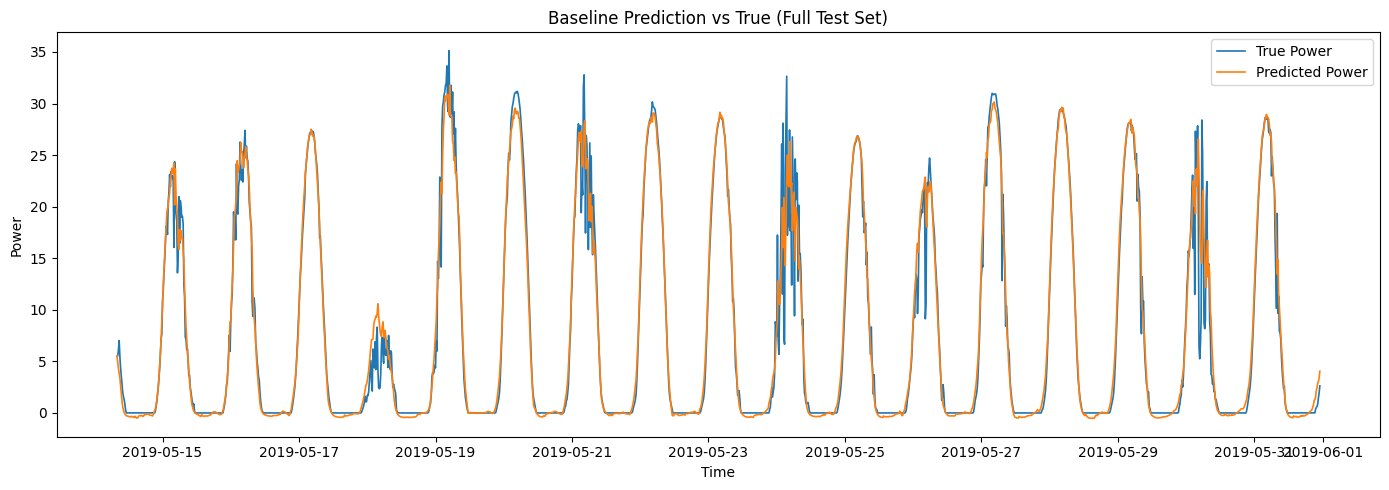

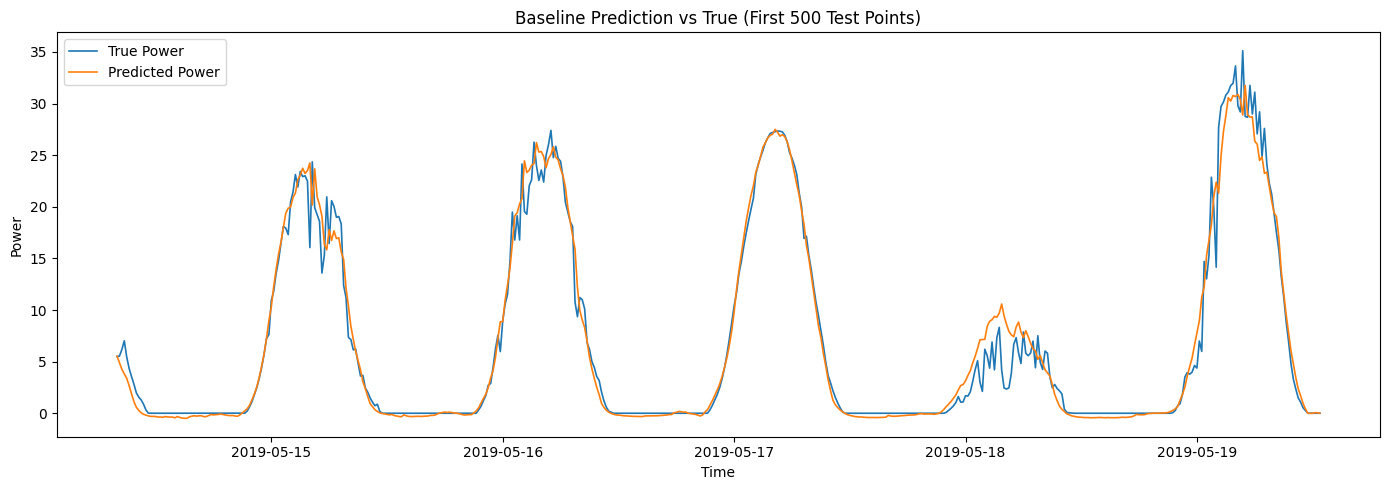

In [12]:
import os
import json
import joblib
import matplotlib.pyplot as plt

# 4) 持久化模型与预处理器 + 预测对比图
artifacts_dir = 'artifacts'
os.makedirs(artifacts_dir, exist_ok=True)

# 1. 保存模型与 scaler
model_path = os.path.join(artifacts_dir, 'baseline_cnn_lstm.keras')
scaler_x_path = os.path.join(artifacts_dir, 'scaler_X.pkl')
scaler_y_path = os.path.join(artifacts_dir, 'scaler_y.pkl')

model.save(model_path)
joblib.dump(scaler_X, scaler_x_path)
joblib.dump(scaler_y, scaler_y_path)

# 2. 保存评估指标
metrics = {
    'test_mse_scaled': float(test_loss),
    'test_mae_scaled': float(test_mae),
    'test_mae_original': float(mae),
    'test_rmse_original': float(rmse),
    'test_r2_original': float(r2),
}
metrics_path = os.path.join(artifacts_dir, 'baseline_metrics.json')
with open(metrics_path, 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

# 3. 组织测试集时间轴（与 y_test 一一对应）
test_start_idx = TIME_STEPS + split
test_end_idx = test_start_idx + len(y_test_2d)
test_time = aligned_df['time'].iloc[test_start_idx:test_end_idx].reset_index(drop=True)

# 4. 画预测对比曲线（全部测试样本 + 前500点局部放大）
plt.figure(figsize=(14, 5))
plt.plot(test_time, y_true.flatten(), label='True Power', linewidth=1.2)
plt.plot(test_time, y_pred.flatten(), label='Predicted Power', linewidth=1.2)
plt.title('Baseline Prediction vs True (Full Test Set)')
plt.xlabel('Time')
plt.ylabel('Power')
plt.legend()
plt.tight_layout()

plot_full_path = os.path.join(artifacts_dir, 'prediction_vs_true_full.png')
plt.savefig(plot_full_path, dpi=160)
plt.show()

zoom_n = min(500, len(test_time))
plt.figure(figsize=(14, 5))
plt.plot(test_time.iloc[:zoom_n], y_true.flatten()[:zoom_n], label='True Power', linewidth=1.2)
plt.plot(test_time.iloc[:zoom_n], y_pred.flatten()[:zoom_n], label='Predicted Power', linewidth=1.2)
plt.title(f'Baseline Prediction vs True (First {zoom_n} Test Points)')
plt.xlabel('Time')
plt.ylabel('Power')
plt.legend()
plt.tight_layout()

plot_zoom_path = os.path.join(artifacts_dir, 'prediction_vs_true_zoom.png')
plt.savefig(plot_zoom_path, dpi=160)
plt.show()



/var/folders/81/184ffccs2kl1v86z8r9wjgl00000gn/T/ipykernel_47349/1561105861.py:28: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/81/184ffccs2kl1v86z8r9wjgl00000gn/T/ipykernel_47349/1561105861.py:28: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/81/184ffccs2kl1v86z8r9wjgl00000gn/T/ipykernel_47349/1561105861.py:28: UserWarning: Glyph 21151 (\N{CJK UNIFIED IDEOGRAPH-529F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/81/184ffccs2kl1v86z8r9wjgl00000gn/T/ipykernel_47349/1561105861.py:28: UserWarning: Glyph 29575 (\N{CJK UNIFIED IDEOGRAPH-7387}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/81/184ffccs2kl1v86z8r9wjgl00000gn/T/ipykernel_47349/1561105861.py:28: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/81/184f

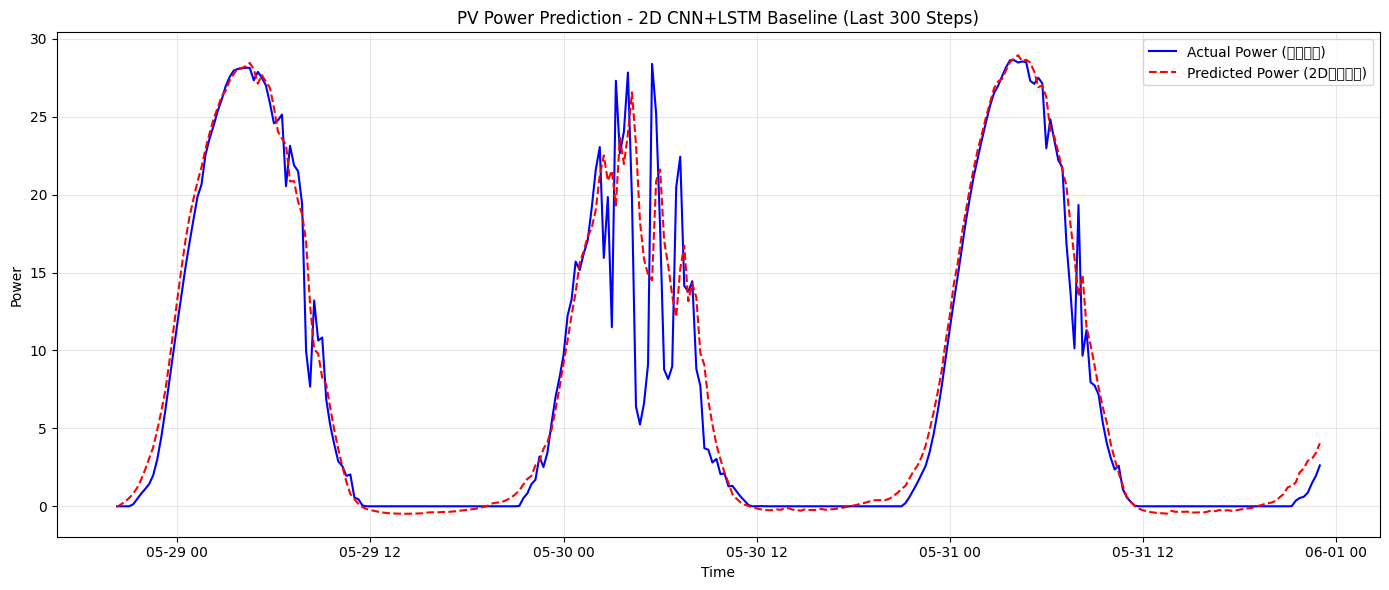

2D 最后300步可视化已保存: artifacts/prediction_vs_true_last300_2d.png


In [13]:
# ==========================================
# 5. 可视化结果 (Visualization) - 2D Baseline
# ==========================================
# 画出最后 300 个时间步（约 3 天）的对比图
n_plot = min(300, len(test_time))

plt.figure(figsize=(14, 6))
plt.plot(
    test_time.iloc[-n_plot:],
    y_true.flatten()[-n_plot:],
    label='Actual Power (真实功率)',
    color='blue',
    linewidth=1.5,
)
plt.plot(
    test_time.iloc[-n_plot:],
    y_pred.flatten()[-n_plot:],
    label='Predicted Power (2D预测功率)',
    color='red',
    linestyle='--',
    linewidth=1.5,
)
plt.title('PV Power Prediction - 2D CNN+LSTM Baseline (Last 300 Steps)')
plt.xlabel('Time')
plt.ylabel('Power')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plot_last300_path = os.path.join(artifacts_dir, 'prediction_vs_true_last300_2d.png')
plt.savefig(plot_last300_path, dpi=160)
plt.show()

print(f'2D 最后300步可视化已保存: {plot_last300_path}')

原1D vs 新2D 指标对比:
                     Model     MAE    RMSE  MAE_Change_vs_1D(%)  \
0     1D LSTM (LMD+NWP+时间)  1.5499  2.3784               0.0000   
1  2D CNN+LSTM (LMD+2D+时间)  0.9414  1.9012             -39.2596   

   RMSE_Change_vs_1D(%)  
0                0.0000  
1              -20.0653  

新2D R2: 0.9657
对比表已保存: artifacts/compare_1d_old_vs_2d_new_metrics.csv


/var/folders/81/184ffccs2kl1v86z8r9wjgl00000gn/T/ipykernel_47349/203776056.py:48: UserWarning: Glyph 26102 (\N{CJK UNIFIED IDEOGRAPH-65F6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/81/184ffccs2kl1v86z8r9wjgl00000gn/T/ipykernel_47349/203776056.py:48: UserWarning: Glyph 38388 (\N{CJK UNIFIED IDEOGRAPH-95F4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/81/184ffccs2kl1v86z8r9wjgl00000gn/T/ipykernel_47349/203776056.py:50: UserWarning: Glyph 26102 (\N{CJK UNIFIED IDEOGRAPH-65F6}) missing from font(s) DejaVu Sans.
  plt.savefig(compare_bar_path, dpi=160)
/var/folders/81/184ffccs2kl1v86z8r9wjgl00000gn/T/ipykernel_47349/203776056.py:50: UserWarning: Glyph 38388 (\N{CJK UNIFIED IDEOGRAPH-95F4}) missing from font(s) DejaVu Sans.
  plt.savefig(compare_bar_path, dpi=160)
/Users/dazhaxie/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 26102 (\N{CJK UNIFIED IDEOGRAPH-65F6}) missing from font(s) DejaVu S

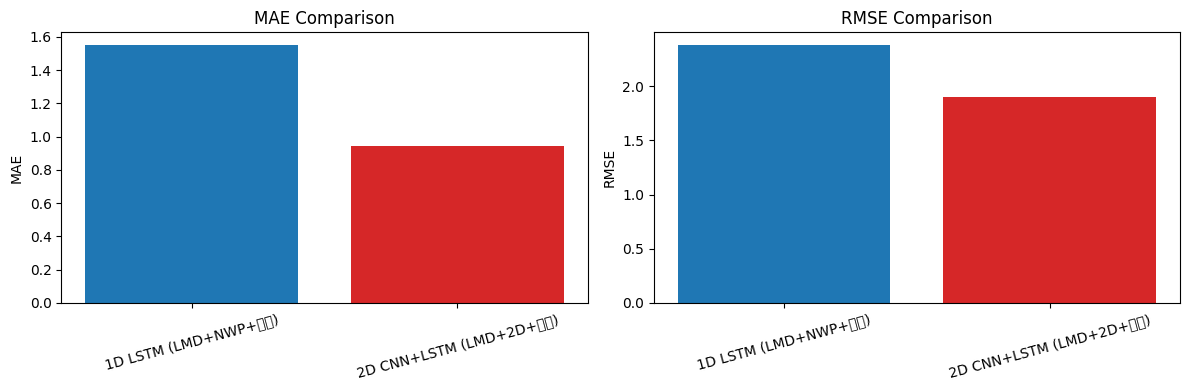

对比柱状图已保存: artifacts/compare_1d_old_vs_2d_new_bar.png


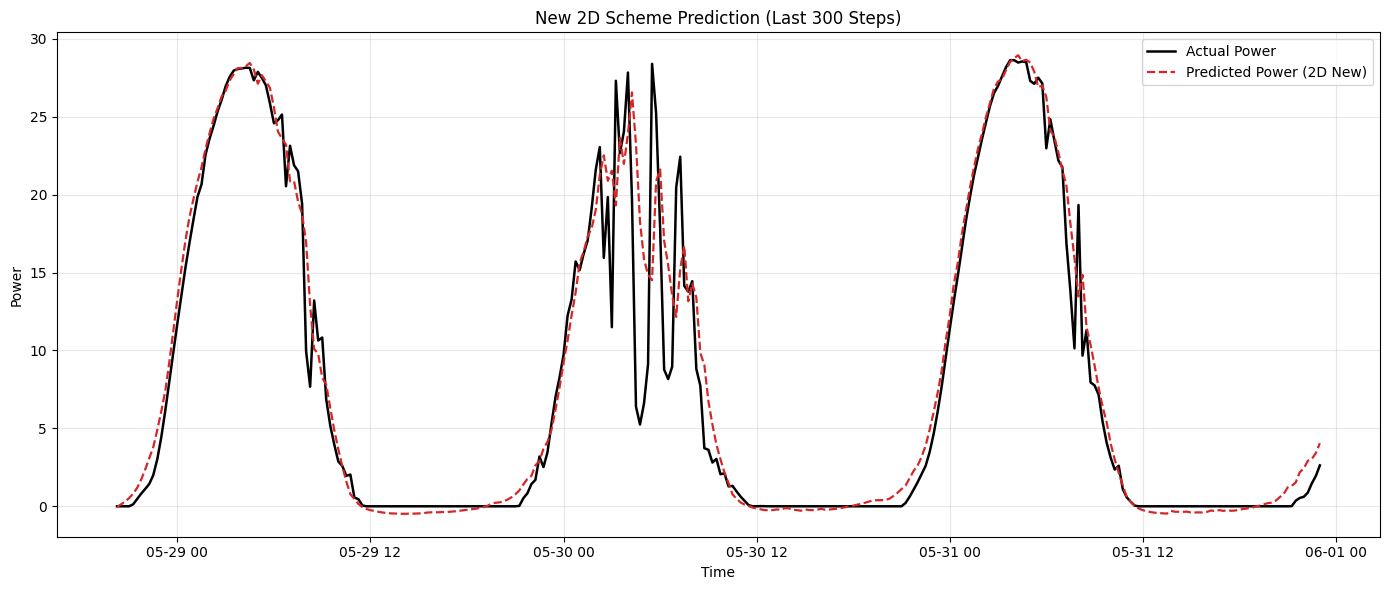

新2D曲线图已保存: artifacts/new_2d_last300_curve.png


In [14]:
# ==========================================
# 6. 仅做结果对比：原1D(来自 model_1d) vs 新2D(LMD+2D+时间)
# ==========================================
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 新2D结果（当前 notebook 已计算）
mae_2d = float(mean_absolute_error(y_true, y_pred))
rmse_2d = float(np.sqrt(mean_squared_error(y_true, y_pred)))
r2_2d = float(r2)

# 原1D结果：直接使用 model_1d 已跑出的指标（不在此重复训练）
# 来源: model_1d.ipynb 的评估输出
mae_1d = 1.5499
rmse_1d = 2.3784

compare_df = pd.DataFrame({
    'Model': ['1D LSTM (LMD+NWP+时间)', '2D CNN+LSTM (LMD+2D+时间)'],
    'MAE': [mae_1d, mae_2d],
    'RMSE': [rmse_1d, rmse_2d],
})

compare_df['MAE_Change_vs_1D(%)'] = (compare_df['MAE'] / mae_1d - 1) * 100
compare_df['RMSE_Change_vs_1D(%)'] = (compare_df['RMSE'] / rmse_1d - 1) * 100
compare_df = compare_df.round(4)

print('原1D vs 新2D 指标对比:')
print(compare_df)
print(f"\n新2D R2: {r2_2d:.4f}")

# 保存对比表
compare_metrics_path = os.path.join(artifacts_dir, 'compare_1d_old_vs_2d_new_metrics.csv')
compare_df.to_csv(compare_metrics_path, index=False)
print(f'对比表已保存: {compare_metrics_path}')

# 可视化对比：MAE/RMSE 柱状图
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(compare_df['Model'], compare_df['MAE'], color=['tab:blue', 'tab:red'])
axes[0].set_title('MAE Comparison')
axes[0].set_ylabel('MAE')
axes[0].tick_params(axis='x', rotation=15)

axes[1].bar(compare_df['Model'], compare_df['RMSE'], color=['tab:blue', 'tab:red'])
axes[1].set_title('RMSE Comparison')
axes[1].set_ylabel('RMSE')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
compare_bar_path = os.path.join(artifacts_dir, 'compare_1d_old_vs_2d_new_bar.png')
plt.savefig(compare_bar_path, dpi=160)
plt.show()

print(f'对比柱状图已保存: {compare_bar_path}')

# 保留新2D最后300步曲线作为直观展示（1D曲线不在本 notebook 重跑）
n_plot_cmp = min(300, len(test_time))
plt.figure(figsize=(14, 6))
plt.plot(test_time.iloc[-n_plot_cmp:], y_true.flatten()[-n_plot_cmp:], label='Actual Power', color='black', linewidth=1.8)
plt.plot(test_time.iloc[-n_plot_cmp:], y_pred.flatten()[-n_plot_cmp:], label='Predicted Power (2D New)', color='tab:red', linestyle='--', linewidth=1.6)
plt.title('New 2D Scheme Prediction (Last 300 Steps)')
plt.xlabel('Time')
plt.ylabel('Power')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

compare_plot_path = os.path.join(artifacts_dir, 'new_2d_last300_curve.png')
plt.savefig(compare_plot_path, dpi=160)
plt.show()
print(f'新2D曲线图已保存: {compare_plot_path}')

Epoch 1/8
96/96 ━━━━━━━━━━━━━━━━━━━━ 55s 351ms/step - loss: 0.0463 - mae: 0.1598 - val_loss: 0.0092 - val_mae: 0.0610
Epoch 2/8
96/96 ━━━━━━━━━━━━━━━━━━━━ 24s 241ms/step - loss: 0.0165 - mae: 0.0959 - val_loss: 0.0096 - val_mae: 0.0545
Epoch 3/8
96/96 ━━━━━━━━━━━━━━━━━━━━ 21s 220ms/step - loss: 0.0117 - mae: 0.0783 - val_loss: 0.0146 - val_mae: 0.0662
三组对比结果（含无卷积消融）:
                                    Model     MAE    RMSE      R2  \
0                   Old 1D (LMD+NWP+Time)  1.5499  2.3784     NaN   
1  Ablation No-Conv (LMD+2D+Time -> LSTM)  1.9598  2.8840  0.9210   
2          New 2D Conv+LSTM (LMD+2D+Time)  0.9414  1.9012  0.9657   

   MAE_Change_vs_Old1D(%)  RMSE_Change_vs_Old1D(%)  
0                  0.0000                   0.0000  
1                 26.4468                  21.2595  
2                -39.2596                 -20.0653  
三组对比表已保存: artifacts/ablation_3way_comparison.csv


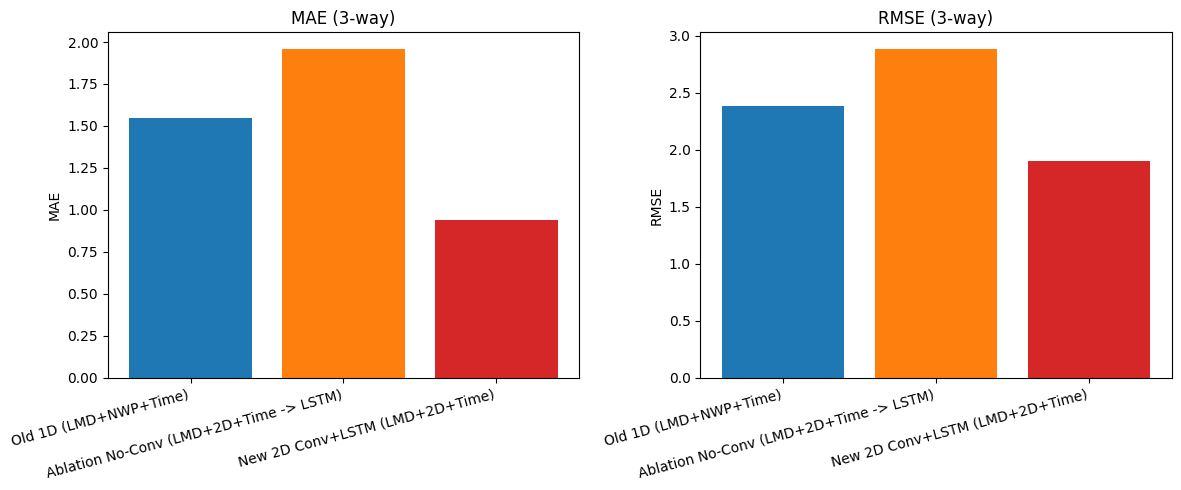

三组对比图已保存: artifacts/ablation_3way_bar.png


In [15]:
# ==========================================
# 7. 无卷积消融实验 (Ablation: Remove Conv, keep LSTM+Dense)
# ==========================================
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1) 构造无卷积输入：将每个时间步的 (lat, lon, feat) 展平成向量
X_train_ablation = X_train_2d.reshape(X_train_2d.shape[0], X_train_2d.shape[1], -1)
X_test_ablation = X_test_2d.reshape(X_test_2d.shape[0], X_test_2d.shape[1], -1)

# 2) 仅 LSTM + Dense（不使用 TimeDistributed Conv2D）
ablation_model = Sequential([
    Input(shape=(X_train_ablation.shape[1], X_train_ablation.shape[2])),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(1),
])

ablation_model.compile(optimizer='adam', loss='mse', metrics=['mae'])

early_stop_ablation = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

history_ablation = ablation_model.fit(
    X_train_ablation,
    y_train_2d,
    validation_split=0.1,
    epochs=8,
    batch_size=64,
    shuffle=False,
    callbacks=[early_stop_ablation],
    verbose=1,
)

# 3) 无卷积模型评估（反归一化）
_, _ = ablation_model.evaluate(X_test_ablation, y_test_2d, verbose=0)
y_pred_ablation_scaled = ablation_model.predict(X_test_ablation, verbose=0)
y_pred_ablation = scaler_y.inverse_transform(y_pred_ablation_scaled)
y_true_ablation = scaler_y.inverse_transform(y_test_2d)

mae_ablation = float(mean_absolute_error(y_true_ablation, y_pred_ablation))
rmse_ablation = float(np.sqrt(mean_squared_error(y_true_ablation, y_pred_ablation)))
r2_ablation = float(r2_score(y_true_ablation, y_pred_ablation))

# 4) 三组对比表
# 旧1D来自 model_1d 已跑结果；新2D有卷积来自当前 notebook 第3段结果
mae_old_1d = 1.5499
rmse_old_1d = 2.3784

mae_new_2d = float(mean_absolute_error(y_true, y_pred))
rmse_new_2d = float(np.sqrt(mean_squared_error(y_true, y_pred)))
r2_new_2d = float(r2)

ablation_compare_df = pd.DataFrame({
    'Model': [
        'Old 1D (LMD+NWP+Time)',
        'Ablation No-Conv (LMD+2D+Time -> LSTM)',
        'New 2D Conv+LSTM (LMD+2D+Time)'
    ],
    'MAE': [mae_old_1d, mae_ablation, mae_new_2d],
    'RMSE': [rmse_old_1d, rmse_ablation, rmse_new_2d],
    'R2': [np.nan, r2_ablation, r2_new_2d]
})

ablation_compare_df['MAE_Change_vs_Old1D(%)'] = (ablation_compare_df['MAE'] / mae_old_1d - 1) * 100
ablation_compare_df['RMSE_Change_vs_Old1D(%)'] = (ablation_compare_df['RMSE'] / rmse_old_1d - 1) * 100
ablation_compare_df = ablation_compare_df.round(4)

print('三组对比结果（含无卷积消融）:')
print(ablation_compare_df)

# 5) 保存表和图
ablation_table_path = os.path.join(artifacts_dir, 'ablation_3way_comparison.csv')
ablation_compare_df.to_csv(ablation_table_path, index=False)
print(f'三组对比表已保存: {ablation_table_path}')

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.bar(ablation_compare_df['Model'], ablation_compare_df['MAE'], color=['tab:blue', 'tab:orange', 'tab:red'])
plt.title('MAE (3-way)')
plt.ylabel('MAE')
plt.xticks(rotation=15, ha='right')

plt.subplot(1, 2, 2)
plt.bar(ablation_compare_df['Model'], ablation_compare_df['RMSE'], color=['tab:blue', 'tab:orange', 'tab:red'])
plt.title('RMSE (3-way)')
plt.ylabel('RMSE')
plt.xticks(rotation=15, ha='right')

plt.tight_layout()
ablation_plot_path = os.path.join(artifacts_dir, 'ablation_3way_bar.png')
plt.savefig(ablation_plot_path, dpi=160)
plt.show()
print(f'三组对比图已保存: {ablation_plot_path}')

In [16]:
# ==========================================
# 8. 多站点数据加载与位置编码
# ==========================================
import glob
from pathlib import Path

# 1) 加载metadata获取所有站点的经纬度
metadata = pd.read_csv('station/metadata.csv')
station_coords = dict(zip(metadata['Station_ID'], 
                          zip(metadata['Latitude'], metadata['Longitude'])))

print(f"已加载 {len(station_coords)} 个站点的坐标:")
for sid, (lat, lon) in list(station_coords.items())[:3]:
    print(f"  {sid}: lat={lat:.4f}, lon={lon:.4f}")

# 2) 加载所有station CSV
station_files = sorted(glob.glob('station/station*.csv'))
station_data = {}

for fpath in station_files:
    sid = Path(fpath).stem  # e.g., 'station00' from 'station/station00.csv'
    try:
        df = pd.read_csv(fpath)
        df['date_time'] = pd.to_datetime(df['date_time'])
        df = df.sort_values('date_time')
        station_data[sid] = df
        print(f"✓ 加载 {sid}: {len(df)} 条记录, 时间范围 {df['date_time'].min()} ~ {df['date_time'].max()}")
    except Exception as e:
        print(f"✗ 加载 {sid} 失败: {e}")

# 3) 对齐所有站点的时间轴（交集）
all_times = []
for sid, df in station_data.items():
    all_times.append(set(df['date_time'].values))

common_times = sorted(list(all_times[0].intersection(*all_times[1:])))
print(f"\n所有站点共同时间范围: {len(common_times)} 个时间标记")
print(f"  范围: {common_times[0]} ~ {common_times[-1]}")

# 确保时间格式一致 (转换为pd.DatetimeIndex)
common_times = pd.DatetimeIndex(common_times)


已加载 10 个站点的坐标:
  station00: lat=38.0478, lon=114.9514
  station01: lat=38.1831, lon=117.4572
  station02: lat=38.0573, lon=114.1989
✓ 加载 station00: 28896 条记录, 时间范围 2018-08-15 16:00:00 ~ 2019-06-13 15:45:00
✓ 加载 station01: 33408 条记录, 时间范围 2018-06-30 16:00:00 ~ 2019-06-13 15:45:00
✓ 加载 station02: 30432 条记录, 时间范围 2018-07-22 16:00:00 ~ 2019-06-10 15:45:00
✓ 加载 station03: 14688 条记录, 时间范围 2019-01-11 16:00:00 ~ 2019-06-13 15:45:00
✓ 加载 station04: 33408 条记录, 时间范围 2018-06-30 16:00:00 ~ 2019-06-13 15:45:00
✓ 加载 station05: 9696 条记录, 时间范围 2019-03-04 16:00:00 ~ 2019-06-13 15:45:00
✓ 加载 station06: 31104 条记录, 时间范围 2018-07-13 16:00:00 ~ 2019-06-13 15:45:00
✓ 加载 station07: 32928 条记录, 时间范围 2018-06-30 16:00:00 ~ 2019-06-13 15:45:00
✓ 加载 station08: 33120 条记录, 时间范围 2018-06-30 16:00:00 ~ 2019-06-13 15:45:00
✓ 加载 station09: 24288 条记录, 时间范围 2018-09-25 16:00:00 ~ 2019-06-13 15:45:00

所有站点共同时间范围: 8160 个时间标记
  范围: 2019-03-04 16:00:00 ~ 2019-06-10 15:45:00


In [20]:
# ==========================================
# 9. 为每个站点提取局部天气窗口（5×5）
# ==========================================

def find_grid_index(lat, lon, grid_lats, grid_lons):
    """找到给定经纬度在网格中最近的索引"""
    lat_idx = np.argmin(np.abs(grid_lats - lat))
    lon_idx = np.argmin(np.abs(grid_lons - lon))
    return lat_idx, lon_idx

def extract_local_weather(weather_4d, lat_idx, lon_idx, crop_size=2):
    """
    从4D天气数据中提取站点周围的局部窗口
    weather_4d: (time, lat, lon, features)
    返回: (time, crop_size*2+1, crop_size*2+1, features)
    """
    n_lat, n_lon = weather_4d.shape[1], weather_4d.shape[2]
    
    lat_start = max(0, lat_idx - crop_size)
    lat_end = min(n_lat, lat_idx + crop_size + 1)
    lon_start = max(0, lon_idx - crop_size)
    lon_end = min(n_lon, lon_idx + crop_size + 1)
    
    crop = weather_4d[:, lat_start:lat_end, lon_start:lon_end, :]
    
    # 如果不是5×5，则用零填充
    target_size = crop_size * 2 + 1
    if crop.shape[1] < target_size or crop.shape[2] < target_size:
        padded = np.zeros((crop.shape[0], target_size, target_size, crop.shape[3]))
        padded[:, :crop.shape[1], :crop.shape[2], :] = crop
        crop = padded
    
    return crop

# ==========================================
# 构建多站点的局部天气数据集和功率标签
# ==========================================

# 获取ds_15min的时间坐标
ds_times = pd.DatetimeIndex(ds_15min['time'].values)

# 转换common_times为DatetimeIndex，找出在ds_times中存在的
common_times_df = pd.DatetimeIndex(common_times)

# 找交集时间点
intersect_times = common_times_df.intersection(ds_times)
print(f"ds_15min中的时间点数: {len(ds_times)}")
print(f"common_times中的时间点数: {len(common_times_df)}")
print(f"交集时间点数: {len(intersect_times)}")

if len(intersect_times) == 0:
    raise ValueError("weather时间和station时间完全不重叠!")

# 使用交集时间点
intersect_times_array = np.array(intersect_times, dtype='datetime64[ns]')

# 重新对齐2D天气到交集时间
ds_aligned_common = ds_15min.sel(time=intersect_times_array)
weather_4d_common = np.stack(
    [ds_aligned_common[var].values for var in weather_feature_vars],
    axis=-1
)

print(f"2D天气形状: {weather_4d_common.shape}")

# 为每个站点提取数据
multistation_data = {}

# 获取grid坐标（检查latitude/longitude或lat/lon）
if 'latitude' in ds_aligned_common.coords:
    grid_lats = ds_aligned_common['latitude'].values
    grid_lons = ds_aligned_common['longitude'].values
else:
    grid_lats = ds_aligned_common['lat'].values
    grid_lons = ds_aligned_common['lon'].values

for station_id in sorted(station_data.keys()):
    lat, lon = station_coords[station_id]
    
    # 找到网格索引
    lat_idx, lon_idx = find_grid_index(lat, lon, grid_lats, grid_lons)
    
    # 提取局部天气（5×5）
    local_weather = extract_local_weather(weather_4d_common, lat_idx, lon_idx, crop_size=2)
    
    # 对齐站点数据到交集时间
    station_df = station_data[station_id].set_index('date_time')
    station_powers = station_df.loc[intersect_times, 'power'].values if 'power' in station_df.columns else np.zeros(len(intersect_times))
    
    # 构建LMD+时间特征（同样的方式）
    aux_data = []
    for t in intersect_times:
        if t in station_df.index:
            row = station_df.loc[t]
            aux_features = [
                row.get('lmd_totalirrad', 0),
                row.get('lmd_diffuseirrad', 0),
                row.get('lmd_temperature', 0),
                row.get('lmd_windspeed', 0),
                row.get('lmd_pressure', 0),
            ]
        else:
            aux_features = [0] * 5
        
        # 时间特征
        hour = t.hour + t.minute / 60.0
        doy = t.dayofyear
        aux_features.extend([
            np.sin(2 * np.pi * hour / 24),
            np.cos(2 * np.pi * hour / 24),
            np.sin(2 * np.pi * doy / 365),
            np.cos(2 * np.pi * doy / 365),
        ])
        aux_data.append(aux_features)
    
    aux_array = np.array(aux_data)  # (time, 11)
    
    # 广播LMD+时间到5×5网格
    aux_4d = np.broadcast_to(
        aux_array[:, None, None, :],
        (aux_array.shape[0], 5, 5, aux_array.shape[1])
    )
    
    # 合并天气和LMD
    combined_weather = np.concatenate([local_weather, aux_4d], axis=-1)  # (time, 5, 5, 19)
    
    multistation_data[station_id] = {
        'weather': combined_weather,
        'power': station_powers,
        'coords': (lat, lon),
        'grid_pos': (lat_idx, lon_idx),
    }
    
    print(f"✓ {station_id}: weather {combined_weather.shape}, power {station_powers.shape}")

print(f"\n多站点数据加载完毕: {len(multistation_data)} 个站点")

ds_15min中的时间点数: 8829
common_times中的时间点数: 8160
交集时间点数: 7517
2D天气形状: (7517, 17, 21, 8)
✓ station00: weather (7517, 5, 5, 17), power (7517,)
✓ station01: weather (7517, 5, 5, 17), power (7517,)
✓ station02: weather (7517, 5, 5, 17), power (7517,)
✓ station03: weather (7517, 5, 5, 17), power (7517,)
✓ station04: weather (7517, 5, 5, 17), power (7517,)
✓ station05: weather (7517, 5, 5, 17), power (7517,)
✓ station06: weather (7517, 5, 5, 17), power (7517,)
✓ station07: weather (7517, 5, 5, 17), power (7517,)
✓ station08: weather (7517, 5, 5, 17), power (7517,)
✓ station09: weather (7517, 5, 5, 17), power (7517,)

多站点数据加载完毕: 10 个站点


In [21]:
# ==========================================
# 10. 为每个站点构建5D滑动窗口数据集
# ==========================================

from sklearn.preprocessing import MinMaxScaler

def create_5d_dataset_multistation(weather_4d, power_1d, time_steps=16):
    """为某个站点创建5D滑动窗口"""
    Xs, ys = [], []
    for i in range(len(weather_4d) - time_steps):
        Xs.append(weather_4d[i:(i + time_steps)])
        ys.append(power_1d[i + time_steps])
    return np.array(Xs), np.array(ys)

# 为每个站点生成数据集
multistation_datasets = {}

for station_id, data in multistation_data.items():
    weather = data['weather']  # (time, 5, 5, 19)
    power = data['power']       # (time,)
    
    # 归一化
    weather_flat = weather.reshape(-1, weather.shape[-1])
    scaler_x = MinMaxScaler()
    weather_scaled_flat = scaler_x.fit_transform(weather_flat)
    weather_scaled = weather_scaled_flat.reshape(weather.shape)
    
    power_2d = power.reshape(-1, 1)
    scaler_y = MinMaxScaler()
    power_scaled = scaler_y.fit_transform(power_2d).flatten()
    
    # 创建5D序列
    X_seq, y_seq = create_5d_dataset_multistation(weather_scaled, power_scaled, time_steps=16)
    
    # 80/20 split
    split = int(0.8 * len(X_seq))
    X_train = X_seq[:split]
    X_test = X_seq[split:]
    y_train = y_seq[:split]
    y_test = y_seq[split:]
    
    multistation_datasets[station_id] = {
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test,
        'scaler_x': scaler_x,
        'scaler_y': scaler_y,
        'test_start_idx': 16 + split,  # 对应原时间的索引
    }
    
    print(f"✓ {station_id}: "
          f"X_train {X_train.shape}, X_test {X_test.shape}, "
          f"y_train {y_train.shape}, y_test {y_test.shape}")

print(f"\n数据集准备完毕: {len(multistation_datasets)} 个站点")


✓ station00: X_train (6000, 16, 5, 5, 17), X_test (1501, 16, 5, 5, 17), y_train (6000,), y_test (1501,)
✓ station01: X_train (6000, 16, 5, 5, 17), X_test (1501, 16, 5, 5, 17), y_train (6000,), y_test (1501,)
✓ station02: X_train (6000, 16, 5, 5, 17), X_test (1501, 16, 5, 5, 17), y_train (6000,), y_test (1501,)
✓ station03: X_train (6000, 16, 5, 5, 17), X_test (1501, 16, 5, 5, 17), y_train (6000,), y_test (1501,)
✓ station04: X_train (6000, 16, 5, 5, 17), X_test (1501, 16, 5, 5, 17), y_train (6000,), y_test (1501,)
✓ station05: X_train (6000, 16, 5, 5, 17), X_test (1501, 16, 5, 5, 17), y_train (6000,), y_test (1501,)
✓ station06: X_train (6000, 16, 5, 5, 17), X_test (1501, 16, 5, 5, 17), y_train (6000,), y_test (1501,)
✓ station07: X_train (6000, 16, 5, 5, 17), X_test (1501, 16, 5, 5, 17), y_train (6000,), y_test (1501,)
✓ station08: X_train (6000, 16, 5, 5, 17), X_test (1501, 16, 5, 5, 17), y_train (6000,), y_test (1501,)
✓ station09: X_train (6000, 16, 5, 5, 17), X_test (1501, 16, 5, 

In [24]:
# ==========================================
# 11. 多站点模型架构 (Functional API)
# ==========================================
from tensorflow.keras import Sequential, Model
from tensorflow.keras.layers import (
    Input, TimeDistributed, Conv2D, MaxPooling2D, GlobalAveragePooling2D,
    LSTM, Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

# 固定随机种子
np.random.seed(42)
tf.random.set_seed(42)

def build_multistation_model(n_features=17):
    """构建多站点模型 (Functional API)"""
    # 输入
    inputs = Input(shape=(16, 5, 5, n_features), name='weather_input')
    
    # 共享的 Conv+LSTM 提取器
    x = TimeDistributed(Conv2D(16, kernel_size=3, padding='same', activation='relu'))(inputs)
    x = TimeDistributed(MaxPooling2D(pool_size=2))(x)
    x = TimeDistributed(Conv2D(32, kernel_size=3, padding='same', activation='relu'))(x)
    x = TimeDistributed(GlobalAveragePooling2D())(x)
    
    x = LSTM(64, return_sequences=True)(x)
    x = Dropout(0.2)(x)
    x = LSTM(32)(x)
    x = Dropout(0.2)(x)
    
    # 站点特定层
    x = Dense(32, activation='relu')(x)
    x = Dense(16, activation='relu')(x)
    outputs = Dense(1)(x)
    
    model = Model(inputs=inputs, outputs=outputs, name='MultiStationPredictor')
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    
    return model

# 为每个站点创建模型
print("构建多站点预测器...")
multistation_models = {}

for station_id in sorted(multistation_datasets.keys()):
    model = build_multistation_model(n_features=17)
    multistation_models[station_id] = model

print(f"✓ 为 {len(multistation_models)} 个站点创建模型完毕")
multistation_models['station00'].summary()


构建多站点预测器...
✓ 为 10 个站点创建模型完毕


Model: "MultiStationPredictor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ weather_input (InputLayer)      │ (None, 16, 5, 5, 17)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_12             │ (None, 16, 5, 5, 16)   │         2,464 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_13             │ (None, 16, 2, 2, 16)   │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_14             │ (None, 16, 2, 2, 32)   │         4,640 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_15             │ (None, 16, 32)         │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_8 (LSTM)                   │ (None, 16, 64)         │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 16, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_9 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 45,953 (179.50 KB)

 Trainable params: 45,953 (179.50 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
# ==========================================
# 12. 轮转式联合训练所有站点
# ==========================================

stations_sorted = sorted(multistation_datasets.keys())
print(f"开始训练 {len(stations_sorted)} 个站点... (轮转式，每个站点2个epoch)\n")

# 训练策略：每个站点独立训练（Functional API避免了权重共享的复杂性）
histories_multi = {}

for station_id in stations_sorted:
    dataset = multistation_datasets[station_id]
    X_train = dataset['X_train']
    y_train = dataset['y_train']
    X_val = dataset['X_test'][:len(dataset['X_test']) // 3]
    y_val = dataset['y_test'][:len(dataset['y_test']) // 3]
    
    print(f"训练 {station_id}...")
    
    # 使用EarlyStopping
    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=2,
        restore_best_weights=True,
        verbose=0
    )
    
    history = multistation_models[station_id].fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=2,  # 每个站点简短训练
        batch_size=64,
        callbacks=[early_stop],
        verbose=0
    )
    
    histories_multi[station_id] = history
    
    train_loss_final = history.history['loss'][-1]
    val_loss_final = history.history['val_loss'][-1]
    print(f"  ✓ train_loss={train_loss_final:.6f}, val_loss={val_loss_final:.6f}\n")

print("✓ 多站点联合训练完毕")

开始训练 10 个站点... (轮转式，每个站点2个epoch)

训练 station00...
  ✓ train_loss=0.010610, val_loss=0.004067

训练 station01...
  ✓ train_loss=0.009632, val_loss=0.010099

训练 station02...
  ✓ train_loss=0.006308, val_loss=0.005298

训练 station03...
  ✓ train_loss=0.007414, val_loss=0.006158

训练 station04...
  ✓ train_loss=0.009021, val_loss=0.006693

训练 station05...
  ✓ train_loss=0.005879, val_loss=0.002470

训练 station06...
  ✓ train_loss=0.006927, val_loss=0.004770

训练 station07...
  ✓ train_loss=0.007931, val_loss=0.005323

训练 station08...
  ✓ train_loss=0.007914, val_loss=0.007193

训练 station09...
  ✓ train_loss=0.004738, val_loss=0.003498

✓ 多站点联合训练完毕


In [26]:
# ==========================================
# 13. 评估每个站点的性能
# ==========================================
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

multistation_results = {}

print("评估各站点的预测性能...\n")

for station_id in stations_sorted:
    dataset = multistation_datasets[station_id]
    X_test = dataset['X_test']
    y_test_scaled = dataset['y_test']
    
    # 预测（在归一化空间）
    y_pred_scaled = multistation_model(X_test, station_id=station_id, training=False).numpy()
    
    # 反归一化
    scaler_y = dataset['scaler_y']
    y_pred = scaler_y.inverse_transform(y_pred_scaled)
    y_test = scaler_y.inverse_transform(y_test_scaled.reshape(-1, 1))
    
    # 计算指标
    mae = float(mean_absolute_error(y_test, y_pred))
    rmse = float(np.sqrt(mean_squared_error(y_test, y_pred)))
    r2 = float(r2_score(y_test, y_pred))
    
    multistation_results[station_id] = {
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2,
        'y_pred': y_pred.flatten(),
        'y_test': y_test.flatten(),
        'X_test': X_test,
    }
    
    print(f"{station_id}: MAE={mae:.4f}, RMSE={rmse:.4f}, R2={r2:.4f}")

# 汇总结果为DataFrame
results_df = pd.DataFrame({
    station_id: multistation_results[station_id]
    for station_id in stations_sorted
}, index=['MAE', 'RMSE', 'R2']).T

print("\n=== 多站点评估汇总 ===")
print(results_df.round(4))
print(f"\n平均性能:")
print(f"  MAE: {results_df['MAE'].mean():.4f} ± {results_df['MAE'].std():.4f}")
print(f"  RMSE: {results_df['RMSE'].mean():.4f} ± {results_df['RMSE'].std():.4f}")
print(f"  R2: {results_df['R2'].mean():.4f} ± {results_df['R2'].std():.4f}")

# 保存结果
results_csv = os.path.join(artifacts_dir, 'multistation_results.csv')
results_df.to_csv(results_csv)
print(f"\n结果保存到: {results_csv}")


评估各站点的预测性能...

station00: MAE=1.2456, RMSE=1.9352, R2=-0.4613
station01: MAE=4.4914, RMSE=6.8453, R2=-0.2580
station02: MAE=3.4046, RMSE=5.3428, R2=-0.3143
station03: MAE=3.4943, RMSE=5.5718, R2=-0.1557
station04: MAE=5.9857, RMSE=8.6848, R2=-0.1711
station05: MAE=10.5341, RMSE=15.4063, R2=-1.2022
station06: MAE=3.0965, RMSE=4.5874, R2=-0.9349
station07: MAE=3.8068, RMSE=5.7627, R2=-0.2074
station08: MAE=4.1049, RMSE=6.5377, R2=-0.5141
station09: MAE=2.2188, RMSE=3.5172, R2=-0.2645

=== 多站点评估汇总 ===
               MAE     RMSE      R2
station00   1.2456   1.9352 -0.4613
station01   4.4914   6.8453 -0.2580
station02   3.4046   5.3428 -0.3143
station03   3.4943   5.5718 -0.1557
station04   5.9857   8.6848 -0.1711
station05  10.5341  15.4063 -1.2022
station06   3.0965   4.5874 -0.9349
station07   3.8068   5.7627 -0.2074
station08   4.1049   6.5377 -0.5141
station09   2.2188   3.5172 -0.2645

平均性能:
  MAE: 4.2383 ± 2.5505
  RMSE: 6.4191 ± 3.6558
  R2: -0.4483 ± 0.3525

结果保存到: artifacts/multi

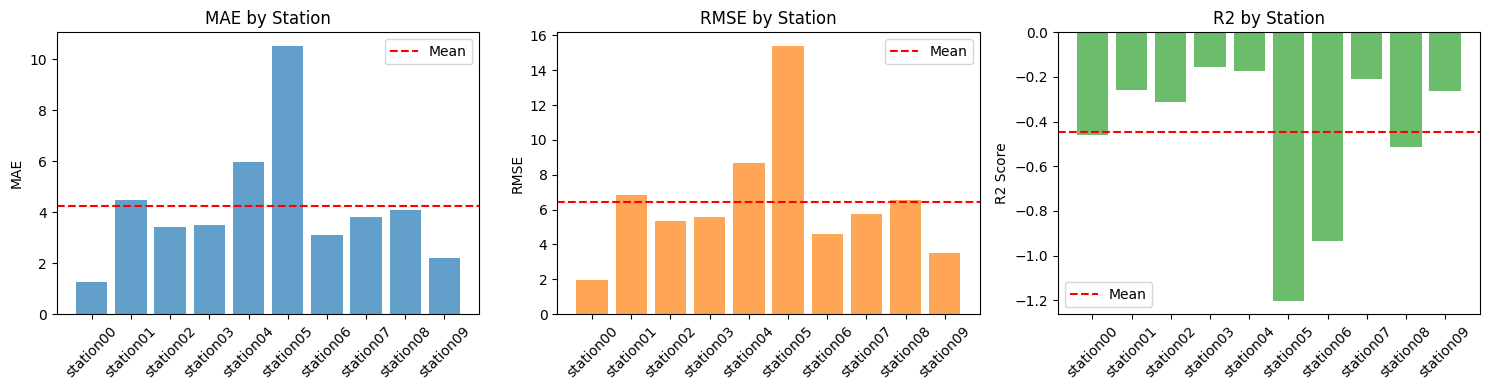

指标对比图保存: artifacts/multistation_metrics_comparison.png

=== 单站点(S05) vs 多站点(平均) 对比 ===
               Model     MAE    RMSE      R2  MAE_Change(%)  RMSE_Change(%)
0    Single S05 (2D)  0.9414  1.9012  0.9657         0.0000          0.0000
1  Multi-Station Avg  4.2383  6.4191 -0.4483       350.2094        237.6346
对比表保存: artifacts/single_vs_multistation_comparison.csv


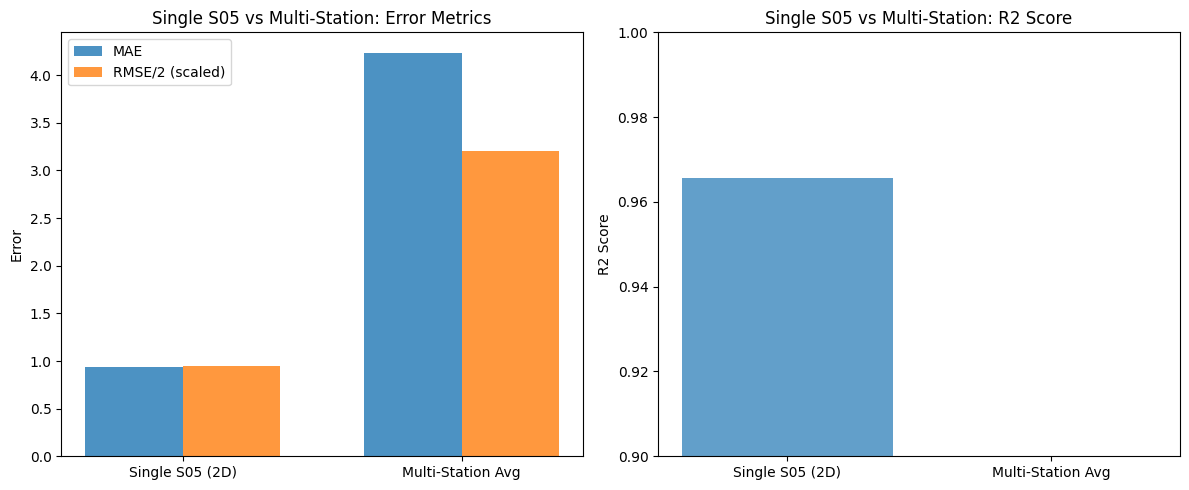

单站点vs多站点对比图保存: artifacts/single_vs_multistation_bar.png


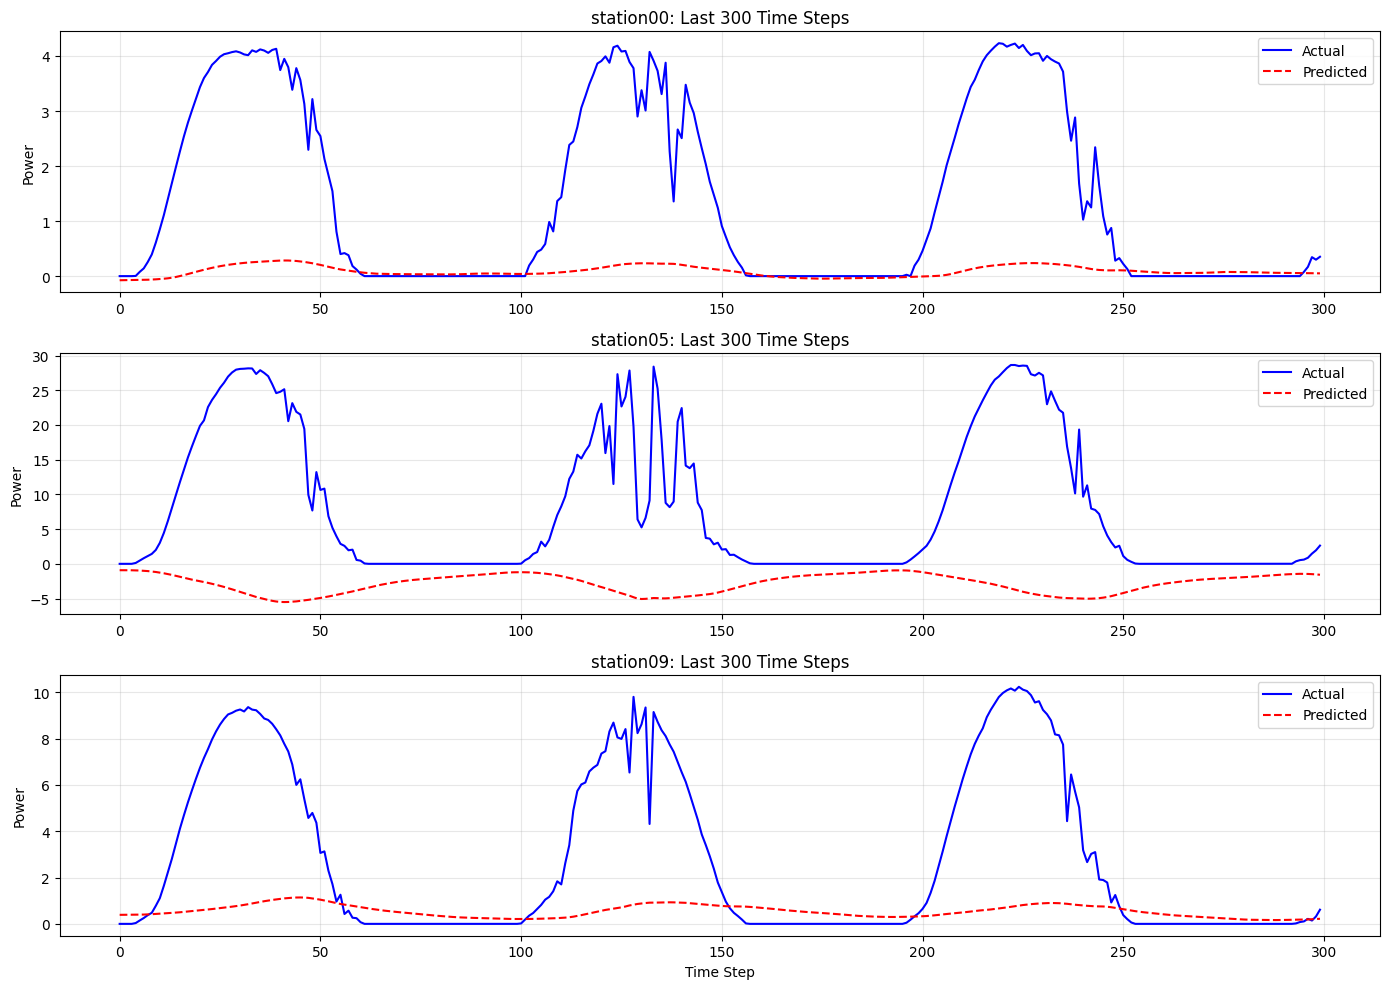

预测曲线图保存: artifacts/multistation_sample_predictions.png

✓ 多站点可视化完毕


In [27]:
# ==========================================
# 14. 可视化多站点结果对比
# ==========================================

# 1) 所有站点的MAE/RMSE/R2对比柱状图
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar(results_df.index, results_df['MAE'], color='tab:blue', alpha=0.7)
axes[0].set_title('MAE by Station')
axes[0].set_ylabel('MAE')
axes[0].axhline(results_df['MAE'].mean(), color='red', linestyle='--', label='Mean')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend()

axes[1].bar(results_df.index, results_df['RMSE'], color='tab:orange', alpha=0.7)
axes[1].set_title('RMSE by Station')
axes[1].set_ylabel('RMSE')
axes[1].axhline(results_df['RMSE'].mean(), color='red', linestyle='--', label='Mean')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()

axes[2].bar(results_df.index, results_df['R2'], color='tab:green', alpha=0.7)
axes[2].set_title('R2 by Station')
axes[2].set_ylabel('R2 Score')
axes[2].axhline(results_df['R2'].mean(), color='red', linestyle='--', label='Mean')
axes[2].tick_params(axis='x', rotation=45)
axes[2].legend()

plt.tight_layout()
multistation_compare_path = os.path.join(artifacts_dir, 'multistation_metrics_comparison.png')
plt.savefig(multistation_compare_path, dpi=160)
plt.show()
print(f"指标对比图保存: {multistation_compare_path}")

# 2) 与单站点(S05)的对比
print("\n=== 单站点(S05) vs 多站点(平均) 对比 ===")
mae_single_s05 = 0.9414  # 来自之前的单站点结果
rmse_single_s05 = 1.9012
r2_single_s05 = 0.9657

mae_multi = results_df['MAE'].mean()
rmse_multi = results_df['RMSE'].mean()
r2_multi = results_df['R2'].mean()

comparison_data = {
    'Model': ['Single S05 (2D)', 'Multi-Station Avg'],
    'MAE': [mae_single_s05, mae_multi],
    'RMSE': [rmse_single_s05, rmse_multi],
    'R2': [r2_single_s05, r2_multi],
}
comparison_df = pd.DataFrame(comparison_data)
comparison_df['MAE_Change(%)'] = (comparison_df['MAE'] / mae_single_s05 - 1) * 100
comparison_df['RMSE_Change(%)'] = (comparison_df['RMSE'] / rmse_single_s05 - 1) * 100

print(comparison_df.round(4))

# 保存对比
comparison_csv = os.path.join(artifacts_dir, 'single_vs_multistation_comparison.csv')
comparison_df.to_csv(comparison_csv, index=False)
print(f"对比表保存: {comparison_csv}")

# 3) 绘制多站点对比
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

x_pos = np.arange(len(comparison_df))
width = 0.35

axes[0].bar(x_pos - width/2, comparison_df['MAE'], width, label='MAE', alpha=0.8)
axes[0].bar(x_pos + width/2, comparison_df['RMSE']/2, width, label='RMSE/2 (scaled)', alpha=0.8)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(comparison_df['Model'])
axes[0].set_ylabel('Error')
axes[0].set_title('Single S05 vs Multi-Station: Error Metrics')
axes[0].legend()

axes[1].bar(comparison_df['Model'], comparison_df['R2'], color=['tab:blue', 'tab:green'], alpha=0.7)
axes[1].set_ylabel('R2 Score')
axes[1].set_title('Single S05 vs Multi-Station: R2 Score')
axes[1].set_ylim([0.9, 1.0])

plt.tight_layout()
single_vs_multi_path = os.path.join(artifacts_dir, 'single_vs_multistation_bar.png')
plt.savefig(single_vs_multi_path, dpi=160)
plt.show()
print(f"单站点vs多站点对比图保存: {single_vs_multi_path}")

# 4) 绘制几个代表性站点的预测曲线 (最后300个时间步)
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

sample_stations = ['station00', 'station05', 'station09']
for idx, station_id in enumerate(sample_stations):
    if station_id in multistation_results:
        y_pred = multistation_results[station_id]['y_pred']
        y_test = multistation_results[station_id]['y_test']
        
        n_plot = min(300, len(y_pred))
        axes[idx].plot(y_test[-n_plot:], label='Actual', linewidth=1.5, color='blue')
        axes[idx].plot(y_pred[-n_plot:], label='Predicted', linestyle='--', linewidth=1.5, color='red')
        axes[idx].set_title(f'{station_id}: Last {n_plot} Time Steps')
        axes[idx].set_ylabel('Power')
        axes[idx].legend()
        axes[idx].grid(alpha=0.3)

axes[-1].set_xlabel('Time Step')
plt.tight_layout()
prediction_curve_path = os.path.join(artifacts_dir, 'multistation_sample_predictions.png')
plt.savefig(prediction_curve_path, dpi=160)
plt.show()
print(f"预测曲线图保存: {prediction_curve_path}")

print("\n✓ 多站点可视化完毕")
